In [1]:
import pandas as pd
import sys
from pathlib import Path 
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import numpy as np

sys.path.insert(0, str(Path("../src").resolve()))
from idx_exchange_data_science.preprocessing import initial_cleaning, clean_living_area, select_training_window,\
    filter_close_price, clean_lot_size, clean_coordinates, CoordinateImputer, add_property_age_at_sale,\
    clean_property_characteristics, clean_postal_code, add_binary_missing_indicators, clean_categorical_features
    
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

## Baseline Model: Linear Regression

This notebook develops and evaluates a baseline Linear Regression model to predict residential property closing prices (ClosePrice) using historical California real estate data.

### Data Loading and Preprocessing

The dataset consists of monthly CSV files from the California Regional Multiple Listing Service (CRMLS), covering January 2024 through April 2026.

The data is split chronologically into training, validation (March 2026), and test (April 2026) sets. Reusable cleaning functions from the idx_exchange.preprocessing_data_science module are applied to prepare the datasets for modeling.

Preprocessing parameters are learned from the training data, with fold-specific fitting used during cross-validation to prevent data leakage.

In [2]:
# Create a Path object to the folder containing the monthly CSV files
data_path = Path("../data")

# Get all the CSV files from the data folder and sort them chronologically by filename
csv_files = sorted(data_path.glob("*.csv"))

In [3]:
# Split the monthly CSV files into training, validation, and test sets
train_files = csv_files[:-2]
validation_file = csv_files[-2]
test_file = csv_files[-1]

In [4]:
# Read each monthly training file into a DataFrame
train_dfs = []

for file in train_files:
    monthly_data = pd.read_csv(file)

    # Extract the year and month from the CSV filename
    source_month = file.stem.replace("CRMLSSold", "").replace("_filled", "")
    monthly_data["SourceMonth"] = source_month[:4] + "-" + source_month[4:6]
    
    train_dfs.append(monthly_data)
    
# Combine the monthly training DataFrames into a single DataFrame
initial_data = pd.concat(train_dfs, ignore_index=True)

/var/folders/s8/2hb9crtx0f59zm5tv6jsyvhm0000gn/T/ipykernel_1032/84281947.py:5: DtypeWarning: Columns (2,36,39,56,74) have mixed types. Specify dtype option on import or set low_memory=False.
  monthly_data = pd.read_csv(file)
/var/folders/s8/2hb9crtx0f59zm5tv6jsyvhm0000gn/T/ipykernel_1032/84281947.py:5: DtypeWarning: Columns (4) have mixed types. Specify dtype option on import or set low_memory=False.
  monthly_data = pd.read_csv(file)
/var/folders/s8/2hb9crtx0f59zm5tv6jsyvhm0000gn/T/ipykernel_1032/84281947.py:5: DtypeWarning: Columns (4,74) have mixed types. Specify dtype option on import or set low_memory=False.
  monthly_data = pd.read_csv(file)


In [5]:
# Load validation and test files
validation_df = pd.read_csv(validation_file)
test_df = pd.read_csv(test_file)

# Add source month to each dataset
for df, file in [(validation_df, validation_file), (test_df, test_file)]:
    source_month = file.stem.replace("CRMLSSold", "").replace("_filled", "")
    df["SourceMonth"] = source_month[:4] + "-" + source_month[4:6]

### Initial Data Cleaning

Apply the initial cleaning rules to remove invalid records, including non-California properties, duplicate transactions, non-single-family residences, inconsistent dates, and invalid closing prices. The same cleaning rules are applied to all three datasets.

In [6]:
# Apply the initial cleaning rules to all datasets
clean_train_df, train_log = initial_cleaning(initial_data)
clean_validation_df, validation_log = initial_cleaning(validation_df)
clean_test_df, test_log = initial_cleaning(test_df)

In [7]:
display(train_log)

,step,Before,Removed,Removed (%),Remaining
0,California filtering,568074,76,0.0134,567998
1,Duplicate removal,567998,2911,0.5125,565087
2,Property-type filtering,565087,280370,49.6154,284717
3,Date consistency,284717,39,0.0137,284678
4,Target cleaning,284678,3,0.0011,284675


### Feature Selection

Select the relevant property features, target variable (ClosePrice), and tracking columns required for preprocessing and modeling. 

Features with 80% or more missing values are excluded from modeling. Based on the full 26 months training dataset, `BasementYN`, `BuildingAreaTotal`, and school-related columns exceed this threshold. 

Note: Detailed geographic layer using school districts will be added in Week 6 (Feature engineering). 

In [8]:
feature_columns = ["AttachedGarageYN", "BathroomsTotalInteger", "BedroomsTotal",
                   "City", "CountyOrParish", "FireplaceYN", "GarageSpaces", "Latitude",
                   "Longitude", "LivingArea","LotSizeSquareFeet", "LotSizeAcres", "NewConstructionYN",
                   "ParkingTotal", "PoolPrivateYN", "PostalCode", "ViewYN", "YearBuilt"]

target_column = ["ClosePrice"]
tracking_columns = ["SourceMonth", "CloseDate"]

key_columns = feature_columns + target_column + tracking_columns


In [9]:
clean_train_df = clean_train_df[key_columns].copy()
clean_validation_df = clean_validation_df[key_columns].copy()
clean_test_df = clean_test_df[key_columns].copy()

In [10]:
# Perserve the datasets before further preprocessing
base_train_df = clean_train_df.copy()
base_validation_df = clean_validation_df.copy()
base_test_df = clean_test_df.copy()

### Training Window Selection and Target Filtering

Select an adjustable training window of X months preceding March 2026. Calculate the 0.5th and 99.5th percentile ClosePrice thresholds from the selected training data and apply the same thresholds to the datasets according to the agreed cleaning rules.

In [11]:
X = 18  # Try 6, 12, 18

# Selcet training window 
clean_train_df = select_training_window(base_train_df, n_months=X, validation_month="2026-03")

print(f"Training window: {X} months")
print(f"Training records: {len(clean_train_df)}")

Training window: 18 months
Training records: 190549


In [12]:
# Calculate thresholds from the selected X-month training window
lower_threshold = clean_train_df["ClosePrice"].quantile(0.005)
upper_threshold = clean_train_df["ClosePrice"].quantile(0.995)

# Remove records outside the training-derived ClosePrice thresholds
clean_train_df, train_price_log = filter_close_price(clean_train_df, lower_threshold, upper_threshold)
clean_validation_df, validation_price_log = filter_close_price(clean_validation_df, lower_threshold, upper_threshold)
clean_test_df, test_price_log = filter_close_price(clean_test_df, lower_threshold, upper_threshold)

In [13]:
# # Apply log transformation to ClosePrice for all datasets
for df in[clean_train_df, clean_validation_df, clean_test_df]:
    df["LogClosePrice"] = np.log1p(df["ClosePrice"])

### Numerical Feature Cleaning

#### LivingArea and LotSizeSquareFeet

Clean numerical property features by removing records with nonpositive LivingArea values while retaining missing values for later imputation. Standardize lot-size measurements by converting valid acreage values to square feet when LotSizeSquareFeet is missing.

In [14]:
# Remove nonpositive LivingArea values while retaining missing values
clean_train_df, train_area_log = clean_living_area(clean_train_df)
clean_validation_df, validation_log = clean_living_area(clean_validation_df)
clean_test_df, test_log = clean_living_area(clean_test_df)

In [15]:
# Clean lot sizes and recover missing square footage using acres
clean_train_df, train_recovered_rows = clean_lot_size(clean_train_df)
clean_validation_df, validation_recovered_rows = clean_lot_size(clean_validation_df)
clean_test_df, test_recovered_rows = clean_lot_size(clean_test_df)

In [16]:
# Summarize the number of recovered lot-size values in each dataset
display(pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Lot sizes recovered": [train_recovered_rows, validation_recovered_rows, test_recovered_rows]}))

,Dataset,Lot sizes recovered
0,Training,15
1,Validation,2
2,Test,0


#### Property Characteristics 

Property characteristics, including bedrooms, bathrooms, garage spaces, and parking counts, are evaluated using provisional plausibility ranges. Invalid values are marked as missing for later imputation rather than removing the corresponding records.

These cleaning rules have not yet been finalized and may be revised following team discussion and further review.

In [17]:
# Clean property characteristics and record invalid values
clean_train_df, train_property_log = clean_property_characteristics(clean_train_df)
clean_validation_df, validation_property_log = clean_property_characteristics(clean_validation_df)
clean_test_df, test_property_log = clean_property_characteristics(clean_test_df)

In [18]:
# Summarize invalid property characteristic values
property_logs = pd.DataFrame({ "Training": train_property_log,
                               "Validation": validation_property_log,
                               "Test": test_property_log})

display(property_logs)

,Training,Validation,Test
BedroomsTotal,61,6,2
BathroomsTotalInteger,44,5,3
GarageSpaces,343,19,21
ParkingTotal,707,45,38


### Geographic Feature Cleaning

Standardize postal codes to five-digit ZIP codes and mark latitude and longitude values outside California's geographic bounds as missing. Missing coordinates will be imputed later using training-derived ZIP-level, county-level, and overall medians within the modeling pipeline.

In [19]:
# Standardize postal codes for all datasets
clean_train_df = clean_postal_code(clean_train_df)
clean_validation_df = clean_postal_code(clean_validation_df)
clean_test_df = clean_postal_code(clean_test_df)

In [20]:
# Mark invalid coordinates as missing
clean_train_df = clean_coordinates(clean_train_df)
clean_validation_df = clean_coordinates(clean_validation_df)
clean_test_df = clean_coordinates(clean_test_df)

### Feature Engineering

Calculate property age and create missingness indicators for binary property features. Missing values are retained for imputation within the modeling pipeline.

In [21]:
# Calculate property age at sale for all datasets
clean_train_df = add_property_age_at_sale(clean_train_df)
clean_validation_df = add_property_age_at_sale(clean_validation_df)
clean_test_df = add_property_age_at_sale(clean_test_df)

In [22]:
# Apply missingness indicator for binary features to all datasets
clean_train_df = add_binary_missing_indicators(clean_train_df)
clean_validation_df = add_binary_missing_indicators(clean_validation_df)
clean_test_df = add_binary_missing_indicators(clean_test_df)

### Categorical Feature Cleaning

Standardize `City`, `CountyOrParish`, and `PostalCode` by converting values to strings, removing surrounding whitespace, and replacing missing values with `"Unknown"`.

Target encoding will be performed within the modeling pipeline. The encoding approach is provisional and subject to further team review.

In [23]:
# Standardize categorical features for target encoding
clean_train_df = clean_categorical_features(clean_train_df)
clean_validation_df = clean_categorical_features(clean_validation_df)
clean_test_df = clean_categorical_features(clean_test_df)

## Preprocessing Pipeline

Define preprocessing steps for numerical, binary, and categorical features using sklearn pipelines. Missing values are imputed using training-derived statistics, numerical features are standardized, and categorical features are target-encoded.

Learned preprocessing parameters within the modeling pipeline are fitted separately for each cross-validation training fold to reduce data leakage. Fixed data-cleaning rules and training-derived ClosePrice thresholds are applied before cross-validation

In [24]:
# define the columns used by each pipeline.
area_columns = ["LivingArea", "LotSizeSquareFeet"]
property_columns = ["BedroomsTotal", "BathroomsTotalInteger", "GarageSpaces", "ParkingTotal"]
coordinate_columns = ["Latitude", "Longitude"]
age_columns = ["PropertyAgeAtSale"]
binary_columns = ["AttachedGarageYN", "FireplaceYN", "NewConstructionYN", "PoolPrivateYN", "ViewYN"]
binary_missing_columns = [f"{col}_Missing" for col in binary_columns]
categorical_columns = ["City", "CountyOrParish","PostalCode"]

In [25]:
# Impute, log-transform, and standardize area features
area_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                          ("log", FunctionTransformer(np.log1p)),
                          ("scaling", StandardScaler())])

# Impute property counts using mode, then standardize
property_pipeline = Pipeline([("imputation", SimpleImputer(strategy="most_frequent")),
                              ("scaling", StandardScaler())])

# Impute and standardize property age
property_age_pipeline = Pipeline([("imputation", SimpleImputer(strategy="median")),
                                  ("scaling", StandardScaler())])

# Standardize coordinates after geographic imputation
coordinate_pipeline = Pipeline([("scaling", StandardScaler())])

# Impute binary features using mode
binary_pipeline = Pipeline([("imputation", SimpleImputer(strategy="most_frequent"))])

# Encode high-cardinality categorical features
categorical_pipeline = Pipeline([("target_encoding", TargetEncoder(target_type="continuous", cv=5,\
                                                                   shuffle=True, random_state=42))])

In [26]:
# Build the ColumnTransformer by assigning each pipeline to its corresponding features.
preprocessor = ColumnTransformer([("area", area_pipeline, area_columns),
                                  ("property", property_pipeline, property_columns),
                                  ("coordinates", coordinate_pipeline, coordinate_columns),
                                  ("property_age", property_age_pipeline, age_columns),
                                  ("binary", binary_pipeline, binary_columns),
                                  ("binary_missing", "passthrough", binary_missing_columns),
                                  ("categorical", categorical_pipeline, categorical_columns)])

In [27]:
# Build the complete modeling pipeline
model_pipeline = Pipeline([("coordinate_imputation", CoordinateImputer()),
                           ("preprocessing", preprocessor),
                           ("model", LinearRegression())])

In [28]:
# Prepare features and target 
model_features = (area_columns + property_columns + coordinate_columns +\
                  age_columns + binary_columns + binary_missing_columns + categorical_columns)

X_train = clean_train_df[model_features].copy()
y_train = clean_train_df["LogClosePrice"]

X_val = clean_validation_df[model_features].copy()
y_val = clean_validation_df["LogClosePrice"]

## Baseline Linear Regression 

### Month-Based Cross-Validation

Use expanding-window cross-validation to evaluate the baseline Linear Regression model on chronological monthly splits.

Each fold trains on all preceding months and validates on the following month. The entire preprocessing pipeline is fitted independently within each training fold to prevent data leakage.

In [29]:
# Sort training records chronologically by source month
train_sorted = clean_train_df.sort_values("SourceMonth").reset_index(drop=True)

# Identify available training months
months = sorted(train_sorted["SourceMonth"].unique())

# Use the last five months for validation
validation_months = months[-5:]

cv_splits = []

for validation_month in validation_months:

    # Train on all months before the validation month
    train_idx = np.where(train_sorted["SourceMonth"] < validation_month)[0]

    # Validate on the selected month
    val_idx = np.where(train_sorted["SourceMonth"] == validation_month)[0]

    cv_splits.append((train_idx, val_idx))

In [30]:
# Calculate Mean Absolute Percentage Error
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Calculate Median Absolute Percentage Error
def mdape(y_true, y_pred):
    return np.median(np.abs((y_true - y_pred) / y_true)) * 100

In [31]:
# Custom scorer (Calculate R² on the original ClosePrice scale)
def close_price_r2(model, X, y):
    predictions_log = model.predict(X)

    actual_prices = np.expm1(y)
    predicted_prices = np.expm1(predictions_log)

    return r2_score(actual_prices, predicted_prices)


# Custom scorer (Calculate MAPE on the original ClosePrice scale)
def dollar_mape(model, X, y):
    predictions_log = model.predict(X)

    actual_prices = np.expm1(y)
    predicted_prices = np.expm1(predictions_log)

    return mape(actual_prices, predicted_prices)


# Custom scorer (Calculate MdAPE on the original ClosePrice scale)
def dollar_mdape(model, X, y):
    predictions_log = model.predict(X)

    actual_prices = np.expm1(y)
    predicted_prices = np.expm1(predictions_log)

    return mdape(actual_prices, predicted_prices)

In [32]:
# Prepare chronologically sorted features and target for cross-validation
X_cv = train_sorted[model_features].copy()
y_cv = train_sorted["LogClosePrice"]

# Evaluate the complete pipeline using monthly folds
cv_scores = cross_validate(model_pipeline, X_cv, y_cv, cv=cv_splits,\
                             scoring={"R²": close_price_r2, "MAPE": dollar_mape, "MdAPE": dollar_mdape}, n_jobs=-1)

# Display cross-validation results
cv_results = pd.DataFrame({ "Validation Month": validation_months, "R²": cv_scores["test_R²"],
                            "MAPE (%)": cv_scores["test_MAPE"], "MdAPE (%)": cv_scores["test_MdAPE"]})

display(cv_results.round(4))

# Display mean cross-validation metrics
print("Mean Cross-Validation Metrics:")
print(cv_results[["R²", "MAPE (%)", "MdAPE (%)"]].mean().round(4))

,Validation Month,R²,MAPE (%),MdAPE (%)
0,2025-10,0.8161,15.6607,11.6555
1,2025-11,0.7994,15.9381,11.8828
2,2025-12,0.8076,16.1226,11.8426
3,2026-01,0.7703,16.6739,12.1089
4,2026-02,0.7932,16.2136,12.1990


Mean Cross-Validation Metrics:
R²            0.7973
MAPE (%)     16.1218
MdAPE (%)    11.9378
dtype: float64


In [33]:
# Display training and validation periods for each fold
for i, (train_idx, val_idx) in enumerate(cv_splits, start=1):

    train_months = train_sorted.iloc[train_idx]["SourceMonth"]
    val_months = train_sorted.iloc[val_idx]["SourceMonth"]

    print(f"Fold {i}: "f"Train {train_months.min()} to {train_months.max()} | "
          f"Validate {val_months.iloc[0]}")

Fold 1: Train 2024-09 to 2025-09 | Validate 2025-10
Fold 2: Train 2024-09 to 2025-10 | Validate 2025-11
Fold 3: Train 2024-09 to 2025-11 | Validate 2025-12
Fold 4: Train 2024-09 to 2025-12 | Validate 2026-01
Fold 5: Train 2024-09 to 2026-01 | Validate 2026-02


### Model Fitting and Validation
Fit the baseline Linear Regression pipeline using the full selected training window and evaluate its performance on the held-out March 2026 validation dataset.

The preprocessing pipeline learns imputation values, scaling parameters, and target encodings from the training data only. Model performance is evaluated using R² and MAE on the original ClosePrice scale, within the previously defined price range.

In [34]:
# Fit the complete pipeline on the full training dataset
model_pipeline.fit(X_train, y_train)

# Predict LogClosePrice for the training dataset
train_predictions_log = model_pipeline.predict(X_train)

# Convert predictions back to the original ClosePrice scale
train_predictions = np.expm1(train_predictions_log)

# Convert actual values back to the original scale
y_train_actual = np.expm1(y_train)

# Predict LogClosePrice for the validation dataset
val_predictions_log = model_pipeline.predict(X_val)

# Convert predictions back to the original ClosePrice scale
val_predictions = np.expm1(val_predictions_log)

# Convert actual values back to the original scale
y_val_actual = np.expm1(y_val)

In [35]:
# Calculate residual (residual = Actual Price - Predicted Price
residuals = y_val_actual - val_predictions

#### March 2026 Validation Results

The baseline Linear Regression model achieved an R² of `0.7969`, an MAE of approximately `$210,747` and an RMSE of approximately `$428,034` on the held-out March 2026 validation dataset.

The R² indicates that the model explains approximately `79.7%` of the variation in sale prices within the selected price range. The substantially higher RMSE relative to MAE suggests that some properties have particularly large prediction errors.

In [36]:
# Evaluate predictions on the original ClosePrice scale
train_r2 = r2_score(y_train_actual, train_predictions)
val_r2 = r2_score(y_val_actual, val_predictions)
val_mae = mean_absolute_error(y_val_actual, val_predictions)
val_rmse = np.sqrt(mean_squared_error(y_val_actual, val_predictions))

print(f"Training R²: {train_r2:.4f}")
print(f"Validation R²: {val_r2:.4f}")
print(f"Validation MAE: ${val_mae:,.2f}")
print(f"Validation RMSE: ${val_rmse:,.2f}")

Training R²: 0.8179
Validation R²: 0.7969
Validation MAE: $210,747.58
Validation RMSE: $428,034.56


 The MAPE indicates an average absolute percentage error of `15.82%`, while the MdAPE indicates that half of the predictions have an absolute percentage error of approximately `11.94%`.

These results are consistent with the month-based cross-validation performance (mean R² = `0.7967`, MAPE = `16.12%`, and MdAPE = `12.01%`) suggesting relatively stable predictive performance across the evaluated months.

In [37]:
# Compare cross-validation and held-out validation performance
results_summary = pd.DataFrame({"Evaluation": ["Month-Based Cross-Validation", "March 2026 Validation"],
                                "R²": [cv_results["R²"].mean(), val_r2],
                                "MAPE (%)": [cv_results["MAPE (%)"].mean(), mape(y_val_actual, val_predictions)],
                                "MdAPE (%)": [cv_results["MdAPE (%)"].mean(), mdape(y_val_actual, val_predictions)]})
display(results_summary)

,Evaluation,R²,MAPE (%),MdAPE (%)
0,Month-Based Cross-Validation,0.797330,16.121776,11.937762
1,March 2026 Validation,0.796876,15.820403,12.014128


### Validation Prediction and Residual Analysis

The actual vs. predicted ClosePrice plot shows that predictions generally follow the observed sale prices, with greater variability at higher property prices.

The residual plot shows that prediction errors become more dispersed as predicted prices increase, suggesting heteroscedasticity. Several extreme residuals are also observed, indicating substantial overprediction or underprediction for some properties.

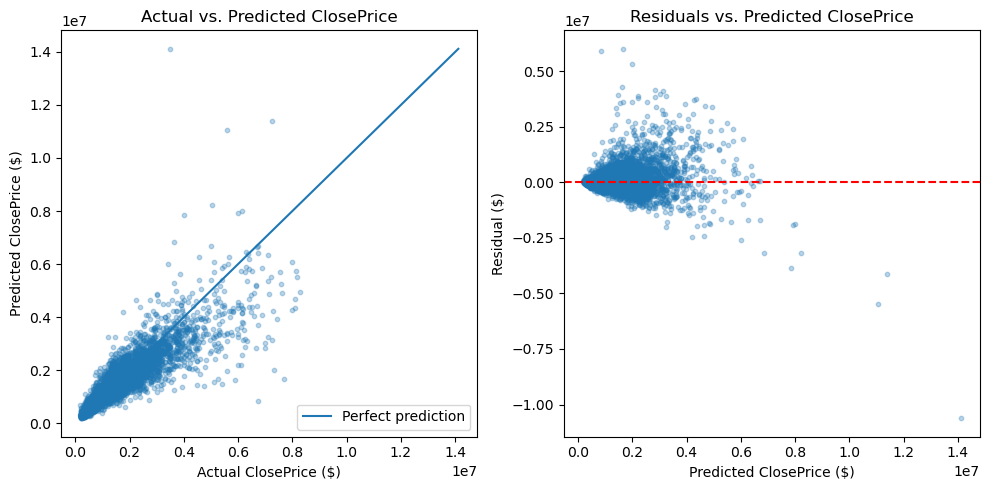

In [38]:
# Visualize validation predictions and residuals
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 1. Actual vs. Predicted ClosePrice
axes[0].scatter(y_val_actual, val_predictions, alpha=0.3, s=10)
price_min = min(y_val_actual.min(), val_predictions.min())
price_max = max(y_val_actual.max(), val_predictions.max())

axes[0].plot([price_min, price_max], [price_min, price_max], label="Perfect prediction")
axes[0].set(title="Actual vs. Predicted ClosePrice", xlabel="Actual ClosePrice ($)", ylabel="Predicted ClosePrice ($)")
axes[0].legend()

# 2. Residuals vs. Predicted ClosePrice
axes[1].scatter(val_predictions, residuals, alpha=0.3, s=10)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(title="Residuals vs. Predicted ClosePrice", xlabel="Predicted ClosePrice ($)", ylabel="Residual ($)")

plt.tight_layout()
plt.show()

### April 2026 Test Results

The R² indicates that the model explains approximately `80.9%` of the variation in sale prices. The MAPE indicates an average absolute percentage error of `15.86%`, while the MdAPE indicates that half of the predictions have an absolute percentage error of approximately `11.90%`.

The test performance is consistent with the month based cross-validation and March 2026 validation results, suggesting that the baseline model generalizes reasonably well to unseen data from the following month.

In [39]:
X_test = clean_test_df[model_features].copy()
y_test = clean_test_df["LogClosePrice"]

# Predict ClosePrice on the April 2026 test dataset
test_predictions_log = model_pipeline.predict(X_test)

# Convert predictions and actual values to the original dollar scale
test_predictions = np.expm1(test_predictions_log)
y_test_actual = np.expm1(y_test)

# Calculate test metrics
test_r2 = r2_score(y_test_actual, test_predictions)
test_mape = mape(y_test_actual, test_predictions)
test_mdape = mdape(y_test_actual, test_predictions)

# Compare cross-validation, validation, and test performance
final_results = pd.DataFrame({
    "Evaluation":["Month-Based Cross-Validation", "March 2026 Validation", "April 2026 Test"],
    "R²":[cv_results["R²"].mean(), val_r2, test_r2],
    "MAPE (%)":[cv_results["MAPE (%)"].mean(), mape(y_val_actual, val_predictions), test_mape],
    "MdAPE (%)": [ cv_results["MdAPE (%)"].mean(), mdape(y_val_actual, val_predictions), test_mdape]})

display(final_results.round(4))

,Evaluation,R²,MAPE (%),MdAPE (%)
0,Month-Based Cross-Validation,0.7973,16.1218,11.9378
1,March 2026 Validation,0.7969,15.8204,12.0141
2,April 2026 Test,0.8091,15.8561,11.9001
